## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

data_path = Path('data/ff_market_daily.parquet')
if not data_path.exists():
    data_path = Path('../data/ff_market_daily.parquet')

df = pd.read_parquet(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

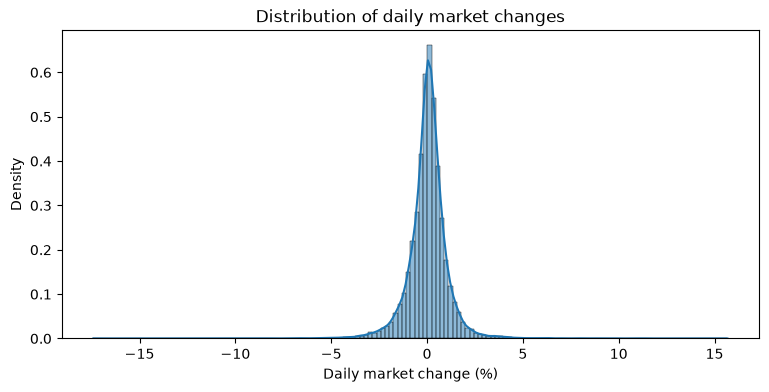

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

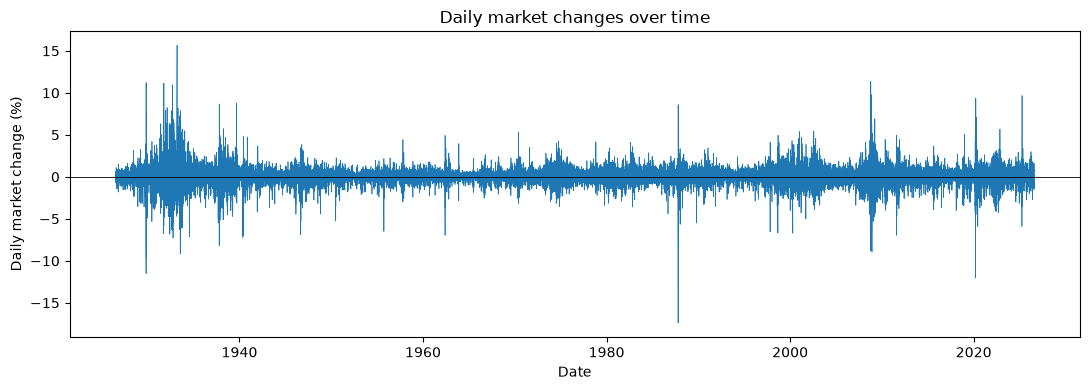

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [ ]:
df['next_market_return_pct'] = df['market_return_pct'].shift(-1)
pairs = df.dropna(subset=['market_return_pct', 'next_market_return_pct']).copy()

pairs['today'] = np.where(pairs['market_return_pct'] > 0, 'Up', 'Down')
pairs['tomorrow'] = np.where(pairs['next_market_return_pct'] > 0, 'Up', 'Down')

joint_pmf = pd.crosstab(pairs['today'], pairs['tomorrow'], normalize=True)
today_marginal = joint_pmf.sum(axis=1)
tomorrow_marginal = joint_pmf.sum(axis=0)
conditional_pmf = pd.crosstab(
    pairs['today'],
    pairs['tomorrow'],
    normalize='index'
)

print('Joint PMF:')
display(joint_pmf)
print("Today's marginal PMF:")
display(today_marginal)
print("Tomorrow's marginal PMF:")
display(tomorrow_marginal)
print('Conditional PMF of tomorrow given today:')
display(conditional_pmf)
print(f"Probability of transitioning to Up: {tomorrow_marginal['Up']:.2%}")
print(f"Probability of transitioning to Down: {tomorrow_marginal['Down']:.2%}")
print(f"Probability of Up after Down: {conditional_pmf.loc['Down', 'Up']:.2%}")
print(f"Probability of Up after Up: {conditional_pmf.loc['Up', 'Up']:.2%}")

Joint PMF:


tomorrow,Down,Up
today,,
Down,0.224720,0.228142
Up,0.228142,0.318996


Today's marginal PMF:


today
Down    0.452862
Up      0.547138
dtype: float64

Tomorrow's marginal PMF:


tomorrow
Down    0.452862
Up      0.547138
dtype: float64

Conditional PMF of tomorrow given today:


tomorrow,Down,Up
today,,
Down,0.496221,0.503779
Up,0.416974,0.583026


Probability of transitioning to Up: 54.71%
Probability of transitioning to Down: 45.29%
Probability of Up after Down: 50.38%
Probability of Up after Up: 58.30%


From these results Up transitions happen more frequently being at 54.71% while down is 45.29%. An Up day is more likely to happen after an Up day being 58.30% of the time while an Up day after a down day is 50.38% of the time.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [ ]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['category'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)
df['next_category'] = df['category'].shift(-1)
df['next_market_return_pct'] = df['market_return_pct'].shift(-1)

category_counts = df['category'].value_counts().sort_index()
print('Number of days in each category:')
display(category_counts)
print('Most common category:', category_counts.idxmax())
print('Least common category:', category_counts.idxmin())
pairs = df.dropna(
    subset=['category', 'next_category', 'next_market_return_pct']
).copy()
joint_pmf = pd.crosstab(
    pairs['category'],
    pairs['next_category'],
    normalize=True
)

today_marginal = joint_pmf.sum(axis=1)
tomorrow_marginal = joint_pmf.sum(axis=0)

print('Joint PMF:')
display(joint_pmf)
print("Today's marginal PMF:")
display(today_marginal)
print("Tomorrow's marginal PMF:")
display(tomorrow_marginal)
print('Five most likely transitions:')
display(joint_pmf.stack().sort_values(ascending=False).head(5))

conditional_pmf = pd.crosstab(
    pairs['category'],
    pairs['next_category'],
    normalize='index'
)

print('Conditional PMF of tomorrow given today:')
display(conditional_pmf)

for category in labels:
    print('Two most likely outcomes after', category)
    display(conditional_pmf.loc[category].sort_values(ascending=False).head(2))
return_summary = pairs.groupby('category', observed=True)['next_market_return_pct'].describe()
print("Summary of tomorrow's returns given today's category:")
display(return_summary)
print("Expected return tomorrow given today's category:")
display(return_summary['mean'])

Number of days in each category:


category
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

Most common category: Small gain
Least common category: Large loss
Joint PMF:


next_category,Large loss,Small loss,Near zero,Small gain,Large gain
category,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


Today's marginal PMF:


category
Large loss    0.104925
Small loss    0.283400
Near zero     0.130861
Small gain    0.372086
Large gain    0.108728
dtype: float64

... (16 outputs left out)

Summary of tomorrow's returns given today's category:


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


Expected return tomorrow given today's category:


category
Large loss   -0.038311
Small loss   -0.043814
Near zero     0.015013
Small gain    0.106810
Large gain    0.163092
Name: mean, dtype: float64

1. Large loss had 2759 instances, small loss had 7452, near zero had 3441, small gain had 9785, and large gain had 2859 instances. This shows that small gain is the most frequent while large loss is the least freqeuent. 2. THe most likely transition in the joint pmf was small gain to small gain being 15.94% and a close second was small gain to small loss being 10.01%. 3. For all states small gain is the most likely next state followed by small loss. The rows are not uniform over each category and fluctuate between the .07-.1 range at lows to .35-.42 at the highs usually. That is still not easy to predict because the largest conditional was small gain followed by small gain which would only be right 42% of the time! 4. The expected returns after a large loss are -.038%, after a small loss are -.044%, after almost no change is 0.015%, after a small gain is 0.107%, and after a large gain is 0.163%. 5. The ranges for each state in order of large loss to large gain are (-17.41-11.22%), (-11.23-11.36%), (-8.19-5.49%), (-8.25-8.67%), (-12.00-15.67%). Interesting when there is large moves the next moves vary alot because after large loss the standard deviation was 1.72% and after large gain was 1.38% std and interesting it was bigger for large loss indicaitng fear has a strong factor on the human mind.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

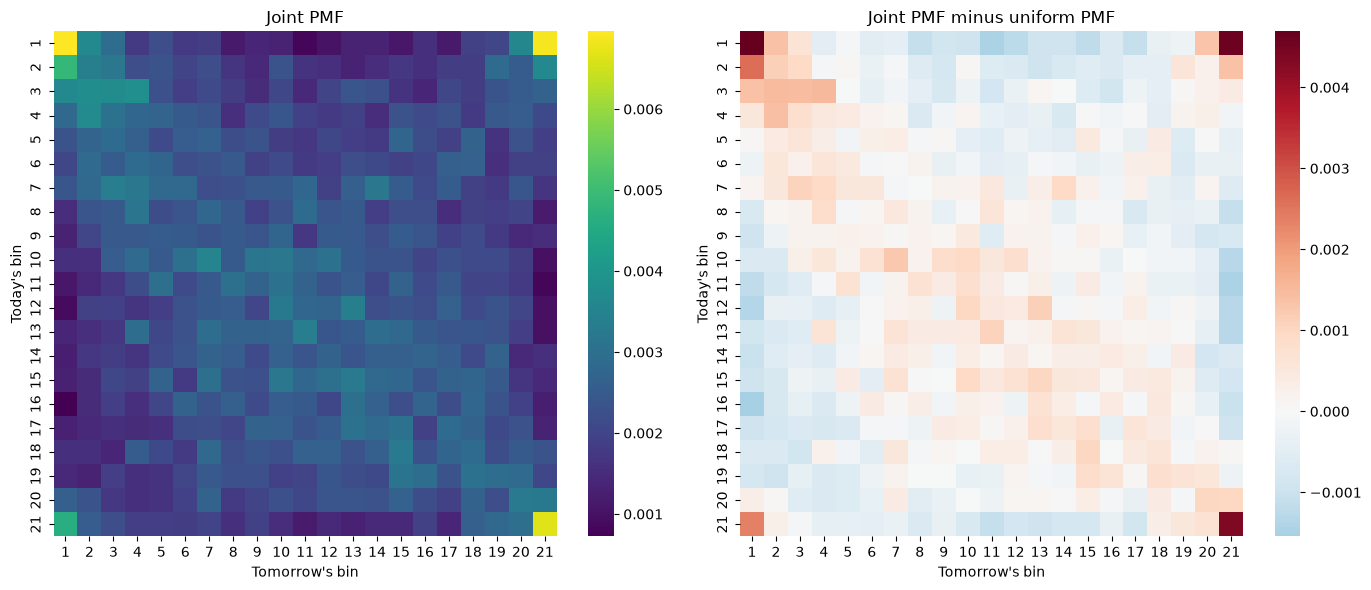

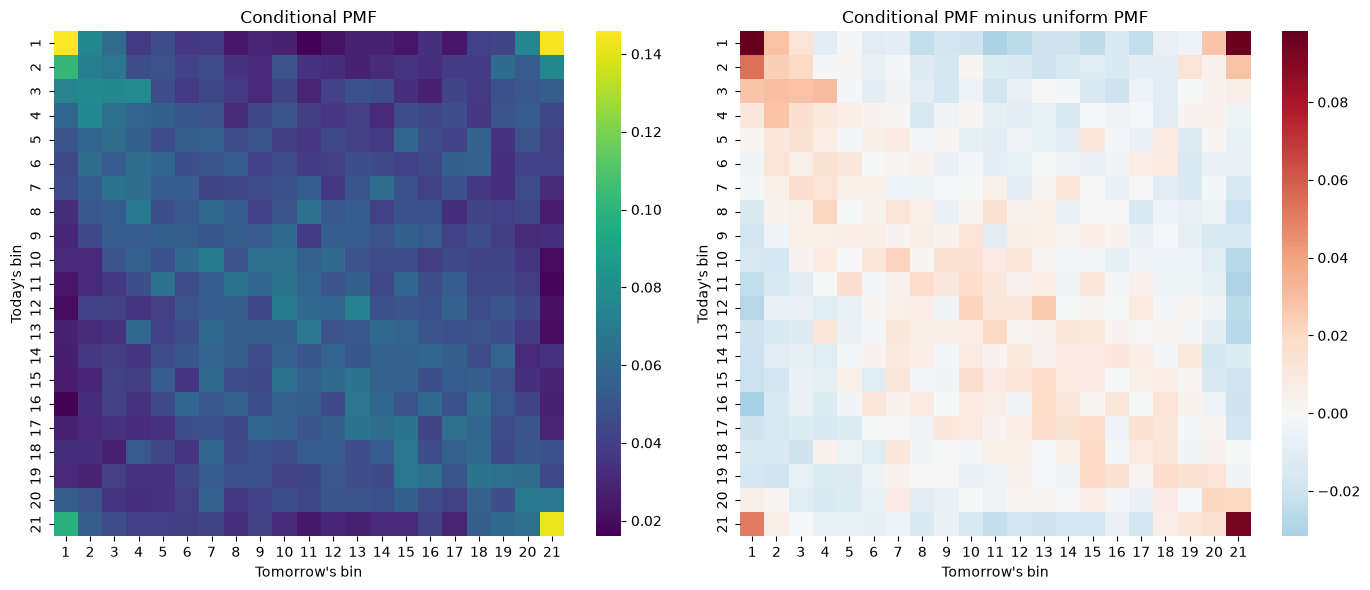

Tomorrow's return statistics for each current bin:


,min,mean,max,std
y_t,,,,
1,-17.41,-0.013713,11.22,2.140465
2,-7.36,-0.076712,6.36,1.285882
3,-8.79,-0.097084,11.36,1.227976
4,-8.28,-0.058594,6.16,1.049607
5,-6.89,-0.024211,4.56,0.989470
6,-11.23,-0.022692,6.37,1.024761
7,-3.94,-0.030241,7.37,0.930389
8,-3.40,-0.014303,4.76,0.835663
9,-6.00,0.025860,5.49,0.853220


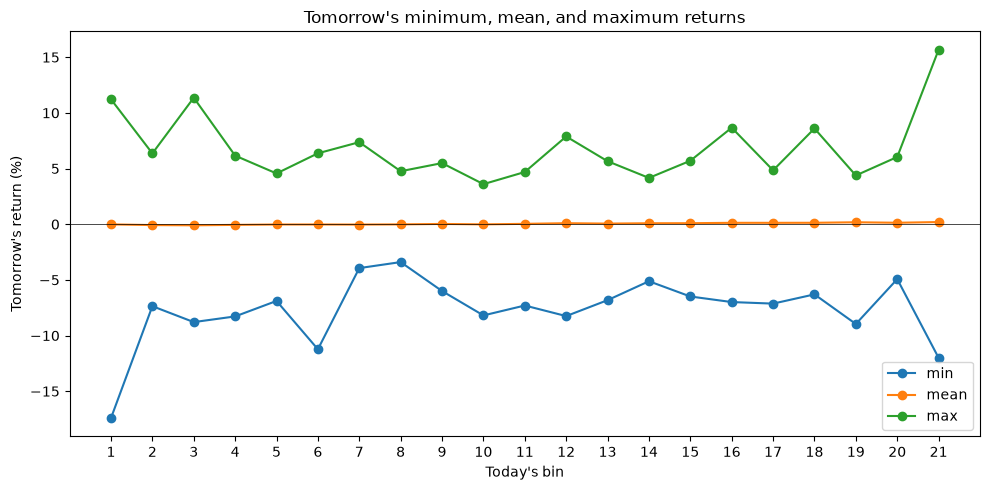

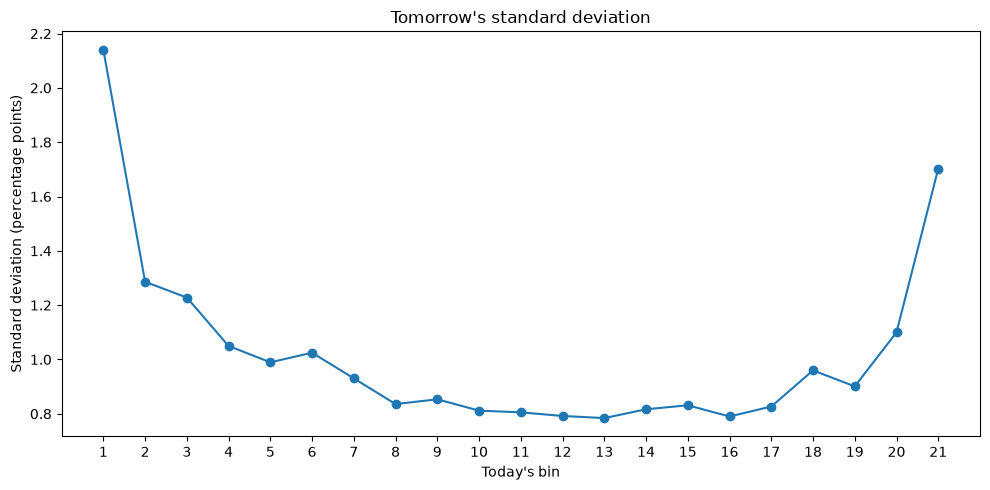

In [ ]:
df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False) + 1
df['y_tp1'] = df['y_t'].shift(-1)
df['next_market_return_pct'] = df['market_return_pct'].shift(-1)

pairs = df.dropna(
    subset=['y_t', 'y_tp1', 'next_market_return_pct']
).copy()

pairs['y_tp1'] = pairs['y_tp1'].astype(int)

joint_pmf = pd.crosstab(
    pairs['y_t'],
    pairs['y_tp1'],
    normalize=True
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(joint_pmf, cmap='viridis', ax=ax[0])
ax[0].set(
    title='Joint PMF',
    xlabel="Tomorrow's bin",
    ylabel="Today's bin"
)

sns.heatmap(joint_pmf - 1 / 21**2, cmap='RdBu_r', center=0, ax=ax[1])
ax[1].set(
    title='Joint PMF minus uniform PMF',
    xlabel="Tomorrow's bin",
    ylabel="Today's bin"
)
plt.tight_layout()
plt.show()

conditional_pmf = pd.crosstab(
    pairs['y_t'],
    pairs['y_tp1'],
    normalize='index'
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(conditional_pmf, cmap='viridis', ax=ax[0])
ax[0].set(
    title='Conditional PMF',
    xlabel="Tomorrow's bin",
    ylabel="Today's bin"
)
sns.heatmap(conditional_pmf - 1 / 21, cmap='RdBu_r', center=0, ax=ax[1])
ax[1].set(
    title='Conditional PMF minus uniform PMF',
    xlabel="Tomorrow's bin",
    ylabel="Today's bin"
)

plt.tight_layout()
plt.show()
return_summary = pairs.groupby('y_t')['next_market_return_pct'].agg(
    ['min', 'mean', 'max', 'std']
)
print("Tomorrow's return statistics for each current bin:")
display(return_summary)
return_summary[['min', 'mean', 'max']].plot(
    figsize=(10, 5),
    marker='o'
)

plt.title("Tomorrow's minimum, mean, and maximum returns")
plt.xlabel("Today's bin")
plt.ylabel("Tomorrow's return (%)")
plt.xticks(range(1, 22))
plt.axhline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

return_summary['std'].plot(figsize=(10, 5), marker='o')

plt.title("Tomorrow's standard deviation")
plt.xlabel("Today's bin")
plt.ylabel('Standard deviation (percentage points)')
plt.xticks(range(1, 22))
plt.tight_layout()
plt.show()

1. It was interesting to see that the corners had the highest probablitlies meaning extreme losses or gains will lead to extreme moves tomorrow wether it be up or down. I also feel like i can see a slight diagnol line meaning that theres a slight continuation bias but i also notice a faint diagnol the other way to. 2. Extreme bins have similar look to the previous heatmap where conditional and joint look awfully similar. 3. The next ranges are widest after extreme current returns where after bin 1 being a large loss returns range from -17.41% to 11.22% and after a large gain being bin 21 it was -12.00 to 15.67% for the return range. The means for the conditionals were small ranging about -.097% to 0.195%. 4. This was i guess the logical conclusion but it was interesting to see a U shape in the standard deviation graoh of the std agaist bin plot with values reaching 2.14% and 1.7% std for the 1st and 21st bin respectively. 5. Its still very hard to predict however there is totally something there as there is deviation from uniform so im sure some strategies could attempt to exploit this however the edge is likely very small and I bet transaction costs could take almost all of it away! Also we have no idea if the patterns will continue into the future! 